# Reproducción de Riess et al. (1998): *Observational Evidence from Supernovae for an Accelerating Universe and a Cosmological Constant*

Este notebook reproduce los cálculos y las figuras principales del paper (AJ 116, 1009) a partir de sus propias tablas, guardadas como CSV en la carpeta `datos_riess1998/`.

**Contenido**

1. Carga y manejo de los datos (Tablas 1–10)
2. Estrellas estándar locales de cada campo (equivalente de la Fig. 2)
3. Curvas de luz de las supernovas nuevas con ajuste SALT2 (Fig. 3)
4. Distancia luminosa y módulo de distancia en FLRW
5. Diagramas de Hubble con ambos métodos (Figs. 4 y 5)
6. Estadística: χ², Bayes y marginalización analítica de $H_0$
7. Contornos en el plano $(\Omega_M,\Omega_\Lambda)$ (Figs. 6 y 7)
8. Edad dinámica del universo (Figs. 8 y 9)
9. Distribución de los parámetros de forma (Fig. 10)
10. Resumen y comparación con la Tabla 8

**Archivos necesarios** (en la misma carpeta que el notebook): `datos_riess1998/` con los CSV y `figuras_originales/` con las figuras del paper.

**Instalación:** la primera celda instala `sncosmo`, `astropy`, `iminuit` y lo demás *en el mismo Python que usa el notebook*. Si prefieres hacerlo a mano en VS Code, escribe en una celda `%pip install sncosmo iminuit` y reinicia el kernel (botón *Restart*).

In [1]:
# Instala lo que falte EN EL MISMO PYTHON QUE USA ESTE NOTEBOOK (VS Code, Jupyter o Colab).
# astropy.table viene incluido en astropy, que se instala junto con sncosmo.
import importlib.util, subprocess, sys
for paquete in ["numpy", "pandas", "scipy", "matplotlib", "astropy", "sncosmo", "iminuit"]:
    if importlib.util.find_spec(paquete) is None:
        print("instalando", paquete, "...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])
print("Python usado por el notebook:", sys.executable)

Python usado por el notebook: /Library/Developer/CommandLineTools/usr/bin/python3


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.integrate import cumulative_trapezoid, quad
from pathlib import Path
import warnings

DATA = Path("datos_riess1998")      # carpeta con los CSV
ORIG = Path("figuras_originales")   # figuras originales extraídas del PDF del paper
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
c = 299792.458                       # velocidad de la luz [km/s]

# Paleta de colores
AZUL, VERDE, MORADO, CELESTE = "#1f4e9c", "#2a9d8f", "#6a4c93", "#48b5e0"
GRIS, TEXTO = "#8A8F98", "#1B2A41"
plt.rcParams.update({
    "font.size": 12, "axes.edgecolor": TEXTO, "axes.labelcolor": TEXTO,
    "xtick.color": TEXTO, "ytick.color": TEXTO, "text.color": TEXTO,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

## 1. Carga y manejo de los datos

| Archivo | Tabla | Contenido |
|---|---|---|
| `tabla1_espectroscopia.csv` | 1 | z de cada SN y si proviene de líneas de la galaxia o de rasgos de la SN |
| `tabla2_fotometria_observada.csv` | 2 | Fotometría observada en los filtros B45, V45, B35, V35 |
| `tabla3_estrellas_estandar_locales.csv` | 3 | Estrellas de calibración de cada campo |
| `tabla4_curvas_luz_reposo.csv` | 4 | Curvas B y V en el sistema en reposo (corrección K aplicada) |
| `tabla5_MLCS_lejanas.csv` / `tabla6_dm15_lejanas.csv` | 5 / 6 | Ajustes MLCS y Δm15(B) de las lejanas: $\mu_0$ |
| `tabla7_snapshot_lejanas.csv` / `tabla9_snapshot_cercanas.csv` | 7 / 9 | Distancias "snapshot" |
| `tabla10_cercanas_MLCS_dm15.csv` | 10 | Las 27 cercanas (MLCS y Δm15) |

En las columnas `*_filtro_alt` o `*_nota`, una letra (R, V, I) indica que esa magnitud se midió en otra banda.

In [3]:
T = {
    "t1":  pd.read_csv(DATA / "tabla1_espectroscopia.csv"),
    "t2":  pd.read_csv(DATA / "tabla2_fotometria_observada.csv"),
    "t3":  pd.read_csv(DATA / "tabla3_estrellas_estandar_locales.csv"),
    "t4":  pd.read_csv(DATA / "tabla4_curvas_luz_reposo.csv"),
    "t5":  pd.read_csv(DATA / "tabla5_MLCS_lejanas.csv"),
    "t6":  pd.read_csv(DATA / "tabla6_dm15_lejanas.csv"),
    "t7":  pd.read_csv(DATA / "tabla7_snapshot_lejanas.csv"),
    "t9":  pd.read_csv(DATA / "tabla9_snapshot_cercanas.csv"),
    "t10": pd.read_csv(DATA / "tabla10_cercanas_MLCS_dm15.csv"),
}
for k, df in T.items():
    print(f"{k:>4}: {len(df):3d} filas | columnas: {list(df.columns)[:6]}...")
T["t5"]

  t1:  14 filas | columnas: ['SN', 'fecha_UT', 'telescopio', 'rango_nm_min', 'rango_nm_max', 'z']...
  t2:  81 filas | columnas: ['SN', 'JD_menos_2450000', 'fecha_UT', 'B45', 'sB45', 'B45_filtro_alt']...
  t3:  54 filas | columnas: ['SN', 'estrella', 'B45', 'sB45', 'B45_nota', 'V45']...
  t4:  86 filas | columnas: ['SN', 'JD_menos_2450000', 'B', 'sigma_B', 'B_obs_en_filtro', 'V']...
  t5:  10 filas | columnas: ['SN', 'z', 'mB_max', 's_mB', 'mV_max', 's_mV']...
  t6:  10 filas | columnas: ['SN', 'z', 'mB_max', 's_mB', 'mV_max', 's_mV']...
  t7:   6 filas | columnas: ['SN', 'z', 't_espectro_dias', 'Delta', 'A_V', 'mu0']...
  t9:   7 filas | columnas: ['SN', 'log_cz', 'Delta', 'A_V', 'mu0', 's_mu0']...
 t10:  27 filas | columnas: ['SN', 'log_cz', 'Delta_MLCS', 'A_B_MLCS', 'mu0_MLCS', 's_mu0_MLCS']...


,SN,z,mB_max,s_mB,mV_max,s_mV,Delta,s_Delta,A_B,mu0,s_mu0
0,1996E,0.43,22.81,0.21,22.72,0.23,-0.08,0.19,0.31,41.74,0.28
1,1996H,0.62,23.23,0.19,23.56,0.18,-0.42,0.16,0.00,42.98,0.17
2,1996I,0.57,23.35,0.28,23.59,0.26,-0.06,0.26,0.00,42.76,0.19
3,1996J,0.30,22.23,0.12,22.21,0.11,-0.22,0.10,0.24,41.38,0.24
4,1996K,0.38,22.64,0.12,22.84,0.14,0.29,0.06,0.00,41.63,0.20
5,1996U,0.43,22.78,0.22,22.98,0.30,-0.52,0.29,0.00,42.55,0.25
6,1997ce,0.44,22.85,0.09,22.95,0.09,0.07,0.08,0.00,41.95,0.17
7,1997cj,0.50,23.19,0.11,23.29,0.12,-0.04,0.11,0.00,42.40,0.17
8,1997ck,0.97,24.78,0.25,NaN,NaN,-0.19,0.23,NaN,44.39,0.30
9,1995K,0.48,22.91,0.13,23.08,0.20,-0.33,0.26,0.00,42.45,0.17


### Construcción de la muestra para el ajuste cosmológico

- Para las cercanas, $z = 10^{\log cz}/c$.
- Para las lejanas se usan las 9 con espectro confirmado: se excluye SN 1997ck, que no tiene clasificación espectroscópica.
- La Tabla 1 indica si el $z$ viene de los rasgos de la SN. En ese caso se suman 2500 km/s en cuadratura a $\sigma_v = 200$ km/s.
- SN 1995K no está en la Tabla 1 (viene de un paper anterior); su $z$ se midió con líneas de la galaxia.

In [4]:
z_de_SN = set(T["t1"].loc[T["t1"].origen_z == "rasgos de la SN", "SN"]) - {"1997cj"}  # 1997cj tiene también z de la galaxia (MMT)
print("z medido con rasgos de la SN:", sorted(z_de_SN))

def muestra(metodo="MLCS", incluir_97ck=False):
    # Devuelve un DataFrame con z, mu0, sigma y la bandera de origen del z.
    t10 = T["t10"]
    col = "MLCS" if metodo == "MLCS" else "dm15"
    cerc = pd.DataFrame({"SN": t10.SN, "z": 10**t10.log_cz / c,
                         "mu": t10[f"mu0_{col}"], "s": t10[f"s_mu0_{col}"], "lejana": False})
    lej = T["t5"] if metodo == "MLCS" else T["t6"]
    if not incluir_97ck:
        lej = lej[lej.SN != "1997ck"]
    lej = pd.DataFrame({"SN": lej.SN, "z": lej.z, "mu": lej.mu0, "s": lej.s_mu0, "lejana": True})
    df = pd.concat([cerc, lej], ignore_index=True)
    df["z_de_SN"] = df.SN.isin(z_de_SN)
    return df

def muestra_snapshot():
    t9, t7 = T["t9"], T["t7"]
    a = pd.DataFrame({"SN": t9.SN, "z": 10**t9.log_cz / c, "mu": t9.mu0, "s": t9.s_mu0, "lejana": False})
    b = pd.DataFrame({"SN": t7.SN, "z": t7.z, "mu": t7.mu0, "s": t7.s_mu0, "lejana": True})
    df = pd.concat([a, b], ignore_index=True)
    df["z_de_SN"] = df.SN.isin({"1995ap"})
    return df

def varianza_total(df, sv=200.0, sv_SN=2500.0):
    # sigma_mu^2 + sigma_v^2 (velocidades peculiares convertidas a magnitudes)
    v = np.where(df.z_de_SN, np.hypot(sv, sv_SN), sv)
    s_v_mag = 5 / np.log(10) * v / (c * df.z)
    return df.s**2 + s_v_mag**2

S_MLCS, S_DM15, S_SNAP = muestra("MLCS"), muestra("dm15"), muestra_snapshot()
print(len(S_MLCS), "SNe con MLCS |", len(S_DM15), "con Δm15 |", len(S_SNAP), "snapshot")
S_MLCS.tail(9)

z medido con rasgos de la SN: ['1995ap', '1996I', '1996K', '1997ce']
36 SNe con MLCS | 36 con Δm15 | 13 snapshot


,SN,z,mu,s,lejana,z_de_SN
27,1996E,0.43,41.74,0.28,True,False
28,1996H,0.62,42.98,0.17,True,False
29,1996I,0.57,42.76,0.19,True,True
30,1996J,0.30,41.38,0.24,True,False
31,1996K,0.38,41.63,0.20,True,True
32,1996U,0.43,42.55,0.25,True,False
33,1997ce,0.44,41.95,0.17,True,True
34,1997cj,0.50,42.40,0.17,True,False
35,1995K,0.48,42.45,0.17,True,False


In [5]:
def mostrar(ruta, titulo=None, ancho=11):
    # Muestra una imagen (PNG) dentro del notebook
    img = plt.imread(ruta); h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(ancho, ancho * h / w))
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None); ax.axis("off")
    if titulo: ax.set_title(titulo)
    plt.show()

## 1b. Fig. 1: espectros de identificación (figura original)

La Fig. 1 del paper **no son curvas de luz**: son los *espectros* de cada supernova (flujo contra longitud de onda en reposo), superpuestos al espectro de una SN Ia cercana de la misma edad (columna "comparación" de la Tabla 1). Sirven para confirmar que cada objeto es una tipo Ia y para medir su $z$. Las curvas de luz son la Fig. 3 (sección 3).

Los espectros **no se publicaron como tabla**, así que no se pueden volver a graficar desde los datos. Las alternativas son mostrar la figura original (abajo), buscar los espectros en archivos como WISeREP, o digitalizarlos con WebPlotDigitizer.

Cómo leerla: el valle de Ca II cerca de 3800 Å y la subida a 3900–4100 Å aparecen en casi todos los paneles. En 96H y 96I, el ruido sobre ~5500 Å son líneas del cielo nocturno. 1997ck solo muestra la línea [O II] de su galaxia, a 3727 Å en reposo (7329 Å observados), de donde sale $z = 0.97$.

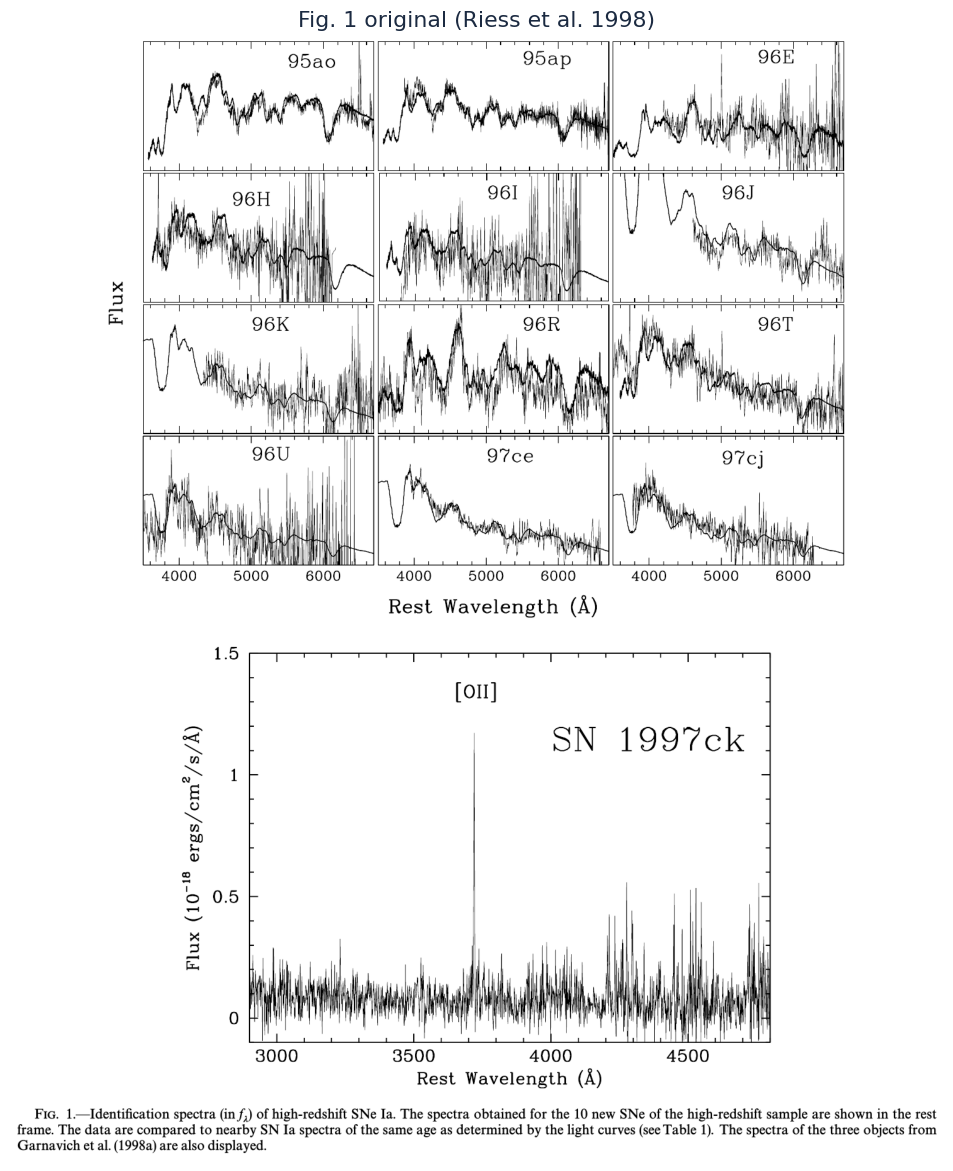

In [6]:
mostrar(ORIG / "fig1_espectros_original.png", "Fig. 1 original (Riess et al. 1998)")

## 2. Estrellas estándar locales (Fig. 2)

La Fig. 2 son **imágenes CCD** de cada campo, tomadas con el telescopio de 4 m de CTIO, con la supernova ("SN") y las estrellas de calibración (1–7) marcadas. Norte arriba, este a la derecha; cada campo mide ~4.9′ de lado.

Esas imágenes y las posiciones de las estrellas **no están publicadas como datos** (solo sus magnitudes, en la Tabla 3), así que la figura no se puede regenerar desde los CSV. Lo que hacemos:

1. mostrar la imagen original, que viene incrustada en el PDF, y cada campo por separado;
2. graficar lo que sí está tabulado: las magnitudes de esas estrellas y de la SN;
3. opcionalmente, descargar una imagen moderna del mismo campo desde el Digitized Sky Survey (requiere internet).

La fotometría de la supernova es *diferencial*: se mide su flujo relativo al de estas estrellas en la misma imagen, de modo que la atmósfera y el telescopio se cancelan:

$$m_{SN} = m_\star - 2.5\log_{10}\frac{F_{SN}}{F_\star}.$$

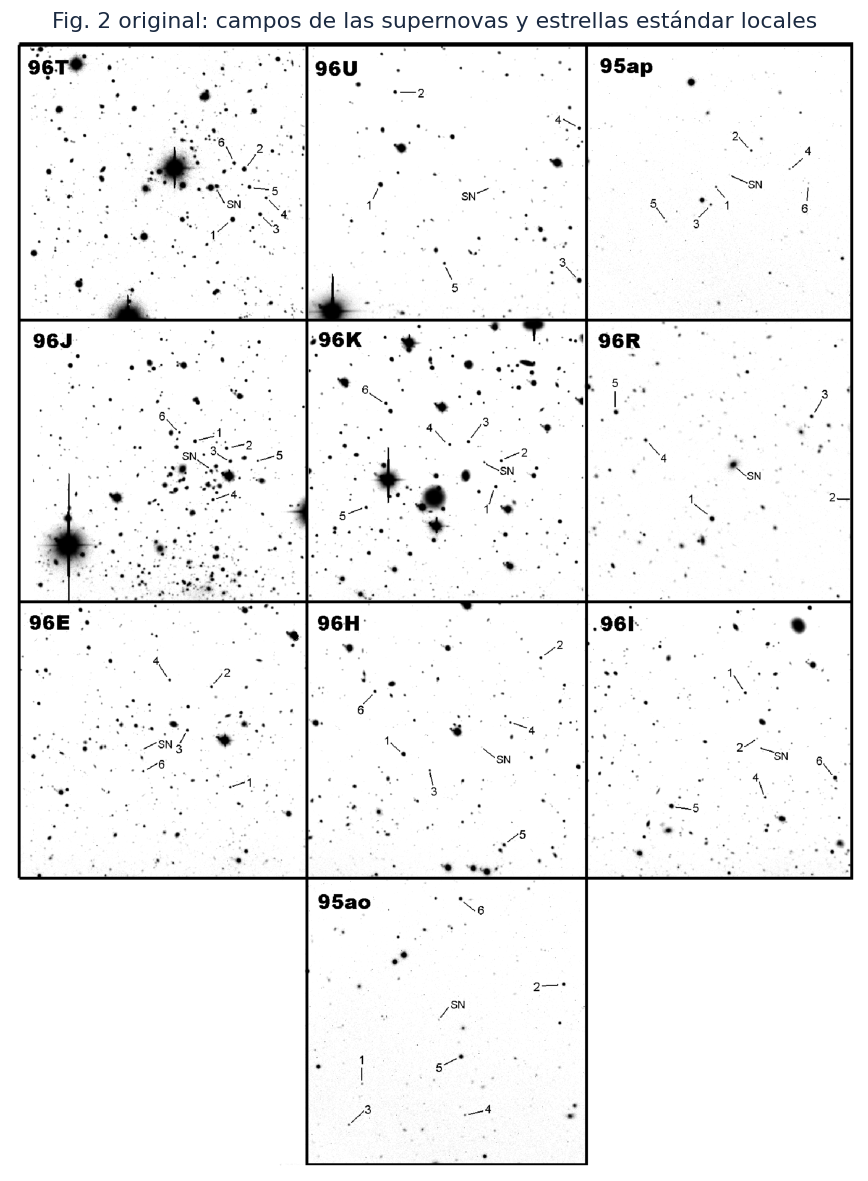

In [7]:
mostrar(ORIG / "fig2_mosaico_original.png", "Fig. 2 original: campos de las supernovas y estrellas estándar locales", ancho=10)

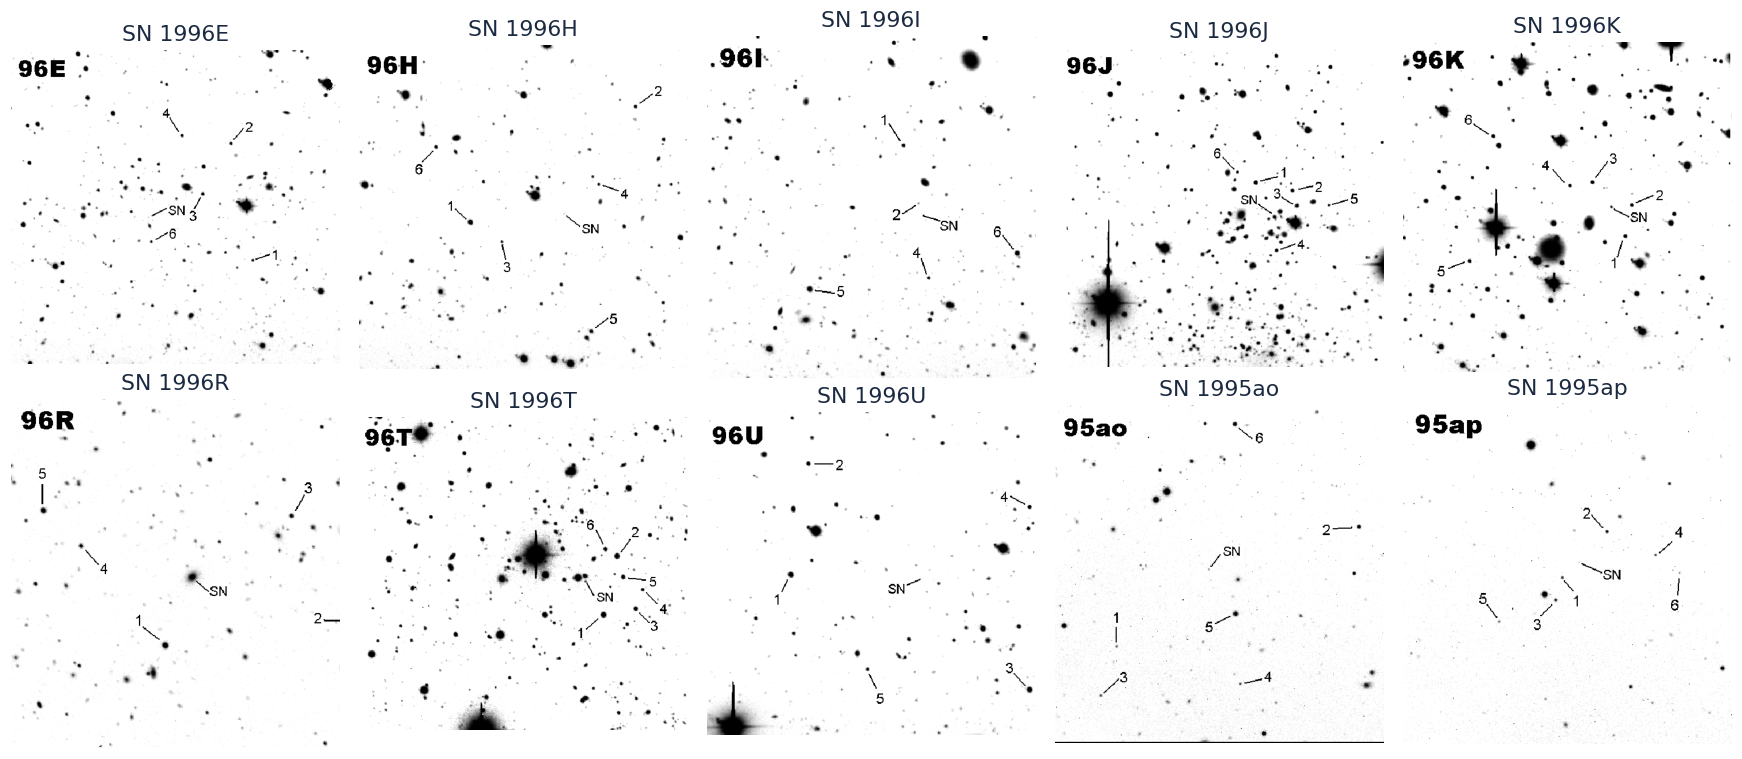

In [8]:
# Cada campo por separado (recortes de la imagen original del paper)
campos_img = ["1996E", "1996H", "1996I", "1996J", "1996K", "1996R", "1996T", "1996U", "1995ao", "1995ap"]
fig, axs = plt.subplots(2, 5, figsize=(16, 7))
for ax, sn in zip(axs.ravel(), campos_img):
    ax.imshow(plt.imread(ORIG / f"fig2_campo_{sn}.png"), cmap="gray"); ax.axis("off")
    ax.set_title(f"SN {sn}")
fig.tight_layout(); plt.show()

### Magnitudes de las estrellas estándar (Tabla 3)

Para cada campo, el diagrama color–magnitud de las estrellas estándar. La estrella morada marca la supernova en su época más brillante (Tabla 2). Las estándares son entre 1 y 5 magnitudes **más brillantes** que la SN: se eligen así para que su propia fotometría tenga poco error (~0.02 mag). La calibración depende entonces de que el detector responda linealmente en ese rango y de restar bien la luz de la galaxia anfitriona.

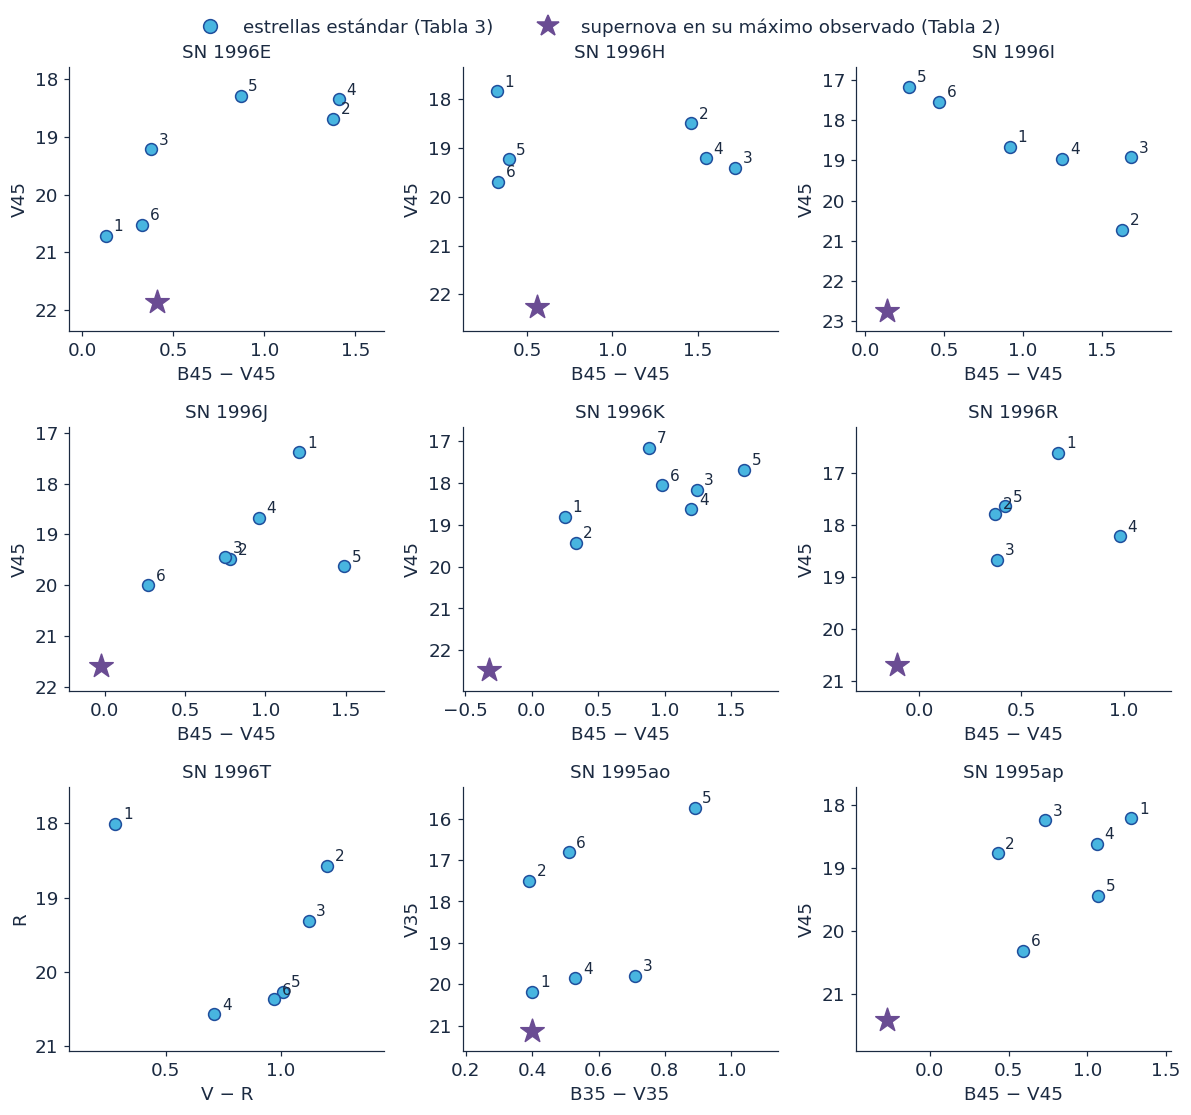

In [9]:
t2, t3 = T["t2"], T["t3"]
campos = ["1996E", "1996H", "1996I", "1996J", "1996K", "1996R", "1996T", "1995ao", "1995ap"]
fig, axs = plt.subplots(3, 3, figsize=(11, 10), sharex=False)
for ax, sn in zip(axs.ravel(), campos):
    st = t3[t3.SN == sn]
    usar45 = st.B45.notna().sum() >= st.B35.notna().sum()
    bB, bV = ("B45", "V45") if usar45 else ("B35", "V35")
    raro = st[f"{bB}_nota"].notna().any() or st[f"{bV}_nota"].notna().any()
    lb = st[f"{bB}_nota"].dropna().iloc[0] if st[f"{bB}_nota"].notna().any() else bB
    lv = st[f"{bV}_nota"].dropna().iloc[0] if st[f"{bV}_nota"].notna().any() else bV
    ok = st[bB].notna() & st[bV].notna()
    col = st.loc[ok, bB] - st.loc[ok, bV]
    ax.scatter(col, st.loc[ok, bV], s=60, color=CELESTE, edgecolor=AZUL, zorder=3, label="estándares")
    for (_, r), cc in zip(st[ok].iterrows(), col):
        ax.annotate(str(r.estrella), (cc, r[bV]), xytext=(5, 3), textcoords="offset points", fontsize=10)
    # SN en su época más brillante (mismo par de filtros, sin bandas alternativas)
    ph = t2[(t2.SN == sn) & t2[bB].notna() & t2[bV].notna()]
    ph = ph[ph[f"{bB}_filtro_alt"].isna() & ph[f"{bV}_filtro_alt"].isna()]
    if len(ph) and not raro:
        r = ph.loc[ph[bB].idxmin()]
        ax.scatter(r[bB] - r[bV], r[bV], marker="*", s=260, color=MORADO, zorder=4, label="SN (máx. observado)")
        ys = list(st.loc[ok, bV]) + [r[bV]]; xs_ = list(col) + [r[bB] - r[bV]]
    else:
        ys = list(st.loc[ok, bV]); xs_ = list(col)
    ax.set_ylim(max(ys) + 0.5, min(ys) - 0.5); ax.set_xlim(min(xs_) - 0.2, max(xs_) + 0.25)
    ax.set_title(f"SN {sn}", fontsize=12)
    ax.set_xlabel(f"{lb} − {lv}"); ax.set_ylabel(lv)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=CELESTE, mec=AZUL, ms=9, label="estrellas estándar (Tabla 3)"),
                    Line2D([], [], marker="*", ls="", color=MORADO, ms=15, label="supernova en su máximo observado (Tabla 2)")],
           loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(); fig.savefig(FIG / "fig2_estandares_locales.png"); plt.show()

### Opcional: imagen moderna del campo (Digitized Sky Survey)

Esta celda busca las coordenadas de la supernova por su nombre (servicio Sesame del CDS) y descarga una imagen DSS2 del mismo campo con `astroquery`. Necesita internet; cambia `DESCARGAR_DSS = True` para usarla. Las supernovas ya no están (se apagaron hace décadas), pero se ve el mismo campo de estrellas que en la Fig. 2. Si el servicio no reconoce el nombre, la celda lo avisa.

In [10]:
%pip install sncosmo iminuit

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [11]:
DESCARGAR_DSS = False
SN_DSS = "SN 1996E"

if DESCARGAR_DSS:
    if importlib.util.find_spec("astroquery") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "astroquery"])
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from astroquery.skyview import SkyView
    try:
        pos = SkyCoord.from_name(SN_DSS)
        print(SN_DSS, "->", pos.to_string("hmsdms"))
        img = SkyView.get_images(position=pos, survey=["DSS2 Red"], radius=2.5 * u.arcmin, pixels=600)[0][0].data
        lo, hi = np.percentile(img, [5, 99.5])
        fig, ax = plt.subplots(figsize=(6, 6))
        ax.imshow(img, cmap="gray_r", vmin=lo, vmax=hi, origin="lower")
        ax.plot(300, 300, marker="o", ms=22, mfc="none", mec=MORADO, mew=2)
        ax.text(320, 330, "SN", color=MORADO, fontsize=13)
        ax.set_title(f"{SN_DSS}: campo de 5′ × 5′ (DSS2 Red)"); ax.axis("off")
        plt.show()
    except Exception as e:
        print("No se pudo descargar la imagen:", e)

## 3. Curvas de luz (Fig. 3)

La Tabla 4 da las magnitudes en las bandas B y V **en reposo**: la corrección K ya fue aplicada,

$$m_X^{\rm reposo} = m_Y^{\rm obs} - K_{XY}(z,\ \text{edad},\ \text{color}).$$

Para el eje "edad" necesitamos la fecha del máximo, que no está tabulada. La obtenemos ajustando un modelo de curva de luz. El paper usa MLCS, cuyas plantillas originales ya no están disponibles en línea. Aquí usamos **SALT2** (`sncosmo`), el estándar actual, con:

- tiempo en reposo $t = JD/(1+z)$, que corrige la dilatación temporal;
- bandas Bessell B y V a $z=0$, porque los datos ya están en reposo;
- parámetros libres: $t_0$ (máximo), $x_0$ (normalización), $x_1$ (forma, equivalente a $\Delta$) y $c$ (color).

La edad es $t - t_0$, y la banda B se desplaza +1 mag para verla mejor, como en el paper.

Las otras cuatro curvas de la Fig. 3 (SN 1995K, 1997ce, 1997cj, 1997ck) son de papers anteriores del equipo y no están en este artículo. SN 1995ao, 1995ap, 1996R y 1996T tienen muy pocos puntos (método snapshot).

In [12]:
import sncosmo
from astropy.table import Table
try:   # algunos entornos bloquean sncosmo.github.io: usamos el espejo en GitHub
    sncosmo.Model(source="salt2")
except Exception:
    import sncosmo.builtins as _b
    _b.DATADIR._remote_root = "https://raw.githubusercontent.com/sncosmo/sncosmo.github.io/master/data/"

t4 = T["t4"]; t5 = T["t5"].set_index("SN")
NUEVAS = ["1996E", "1996H", "1996I", "1996J", "1996K", "1996U"]

def tabla_sncosmo(sn):
    z = t5.loc[sn, "z"]; d = t4[t4.SN == sn]; filas = []
    for _, r in d.iterrows():
        for banda, m, s in [("bessellb", r.B, r.sigma_B), ("bessellv", r.V, r.sigma_V)]:
            if pd.notna(m):
                f = 10**(-0.4 * (m - 25.0))                  # flujo con punto cero 25
                filas.append((r.JD_menos_2450000 / (1 + z), banda, f, f * s * np.log(10) / 2.5, 25.0, "vega"))
    return Table(rows=filas, names=("time", "band", "flux", "fluxerr", "zp", "zpsys")), z

AJ = {}
for sn in NUEVAS:
    tab, z = tabla_sncosmo(sn)
    modelo = sncosmo.Model(source="salt2"); modelo.set(z=0.0)
    res, fit = sncosmo.fit_lc(tab, modelo, ["t0", "x0", "x1", "c"], bounds={"x1": (-3, 3), "c": (-0.3, 0.6)})
    AJ[sn] = dict(tab=tab, fit=fit, res=res, z=z)

resumen = pd.DataFrame({sn: {
    "z": a["z"], "JD_max": a["res"].parameters[1] * (1 + a["z"]),
    "x1": a["res"].parameters[3], "c": a["res"].parameters[4],
    "mB_max SALT2": a["fit"].bandmag("bessellb", "vega", a["res"].parameters[1]),
    "mB_max Tabla 5": t5.loc[sn, "mB_max"],
    "mV_max SALT2": a["fit"].bandmag("bessellv", "vega", a["res"].parameters[1]),
    "mV_max Tabla 5": t5.loc[sn, "mV_max"],
    "chi2/gdl": f'{a["res"].chisq:.1f}/{a["res"].ndof}'} for sn, a in AJ.items()}).T
resumen.round(2)

,z,JD_max,x1,c,mB_max SALT2,mB_max Tabla 5,mV_max SALT2,mV_max Tabla 5,chi2/gdl
1996E,0.43,122.177682,-0.862948,0.15842,22.863493,22.81,22.69051,22.72,5.7/11
1996H,0.62,120.277913,2.999999,-0.3,23.193179,23.23,23.483935,23.56,30.8/19
1996I,0.57,128.200636,-1.586327,-0.223143,23.398554,23.35,23.611529,23.59,8.4/14
1996J,0.3,136.066872,-0.706367,0.177267,22.294466,22.23,22.102501,22.21,230.5/17
1996K,0.38,143.493979,-1.225386,-0.144773,22.777474,22.64,22.910873,22.84,40.7/30
1996U,0.43,163.330914,-0.558619,-0.197492,22.802509,22.78,22.989342,22.98,3.3/7


Los máximos de SALT2 coinciden con los de MLCS (Tabla 5) dentro de ~0.1 mag. Dos casos merecen comentario:

- **SN 1996J** tiene un χ² malo. El propio paper lo menciona: parte de sus datos se tomaron con filtros pensados para $z=0.45$ cuando la SN está a $z=0.30$.
- **SN 1996H** queda en el borde de los parámetros ($x_1$, $c$), porque se descubrió cerca del máximo y su color está mal determinado.

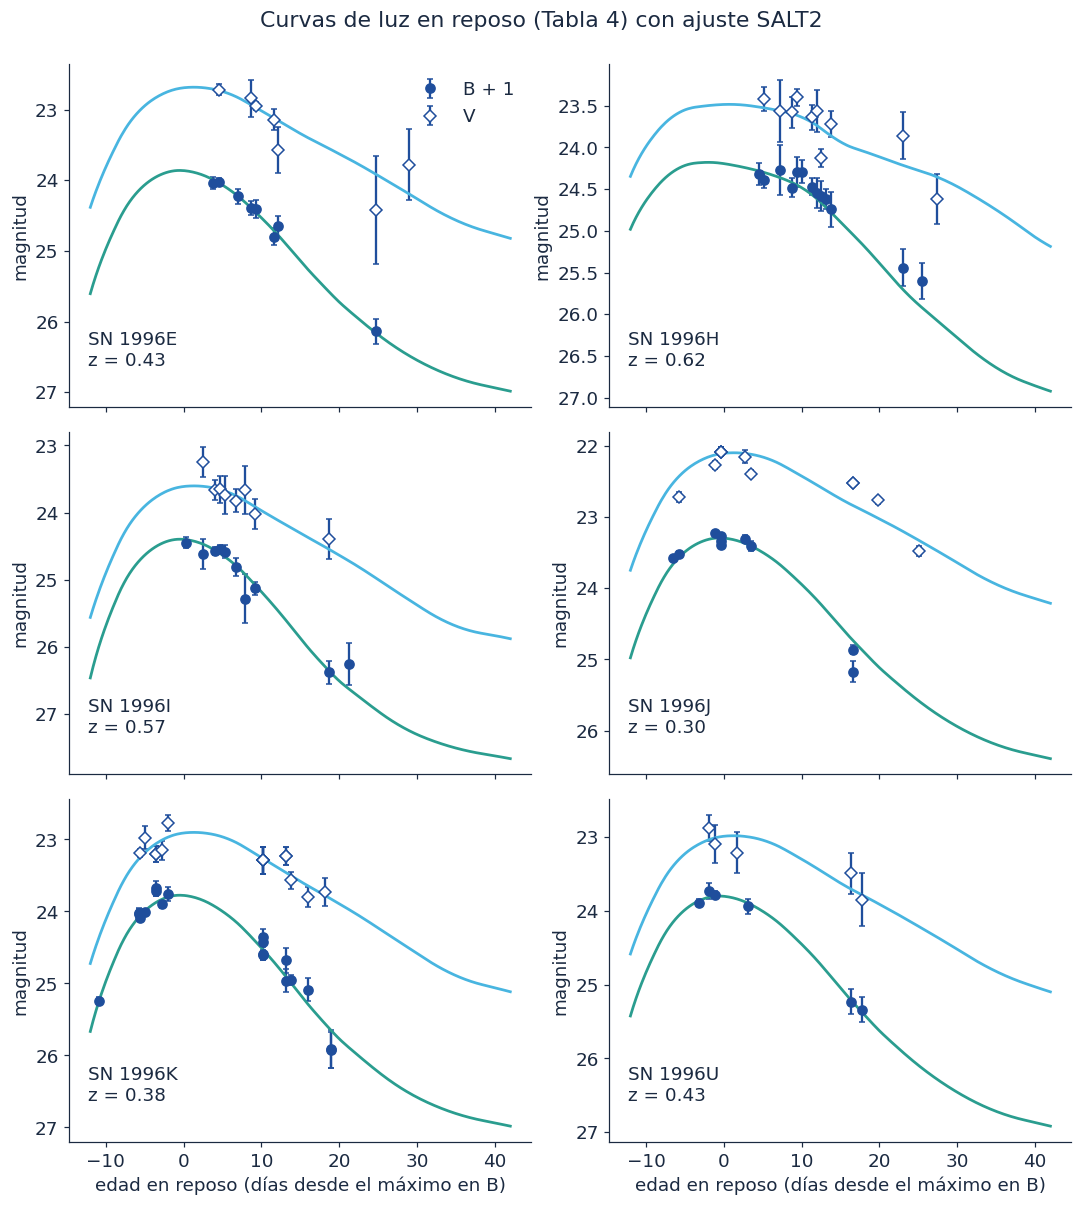

In [13]:
fig, axs = plt.subplots(3, 2, figsize=(10, 11), sharex=True)
for ax, sn in zip(axs.ravel(), NUEVAS):
    a = AJ[sn]; t0 = a["res"].parameters[1]; tab = a["tab"]
    tt = np.linspace(t0 - 12, t0 + 42, 300)
    for banda, off, mk, lab in [("bessellb", 1.0, "o", "B + 1"), ("bessellv", 0.0, "D", "V")]:
        k = tab["band"] == banda
        m = 25 - 2.5 * np.log10(tab["flux"][k]); e = 2.5 / np.log(10) * tab["fluxerr"][k] / tab["flux"][k]
        ax.errorbar(tab["time"][k] - t0, m + off, e, fmt=mk, ms=6,
                    mfc=AZUL if banda == "bessellb" else "white", mec=AZUL, ecolor=AZUL, capsize=2, label=lab)
        ax.plot(tt - t0, a["fit"].bandmag(banda, "vega", tt) + off, color=VERDE if banda == "bessellb" else CELESTE, lw=1.8)
    ax.invert_yaxis()
    ax.text(0.04, 0.12, f"SN {sn}\nz = {a['z']:.2f}", transform=ax.transAxes, fontsize=12)
    ax.set_ylabel("magnitud")
axs[0, 0].legend(frameon=False, loc="upper right")
for ax in axs[-1]: ax.set_xlabel("edad en reposo (días desde el máximo en B)")
fig.suptitle("Curvas de luz en reposo (Tabla 4) con ajuste SALT2", y=0.995)
fig.tight_layout(); fig.savefig(FIG / "fig3_curvas_de_luz.png"); plt.show()

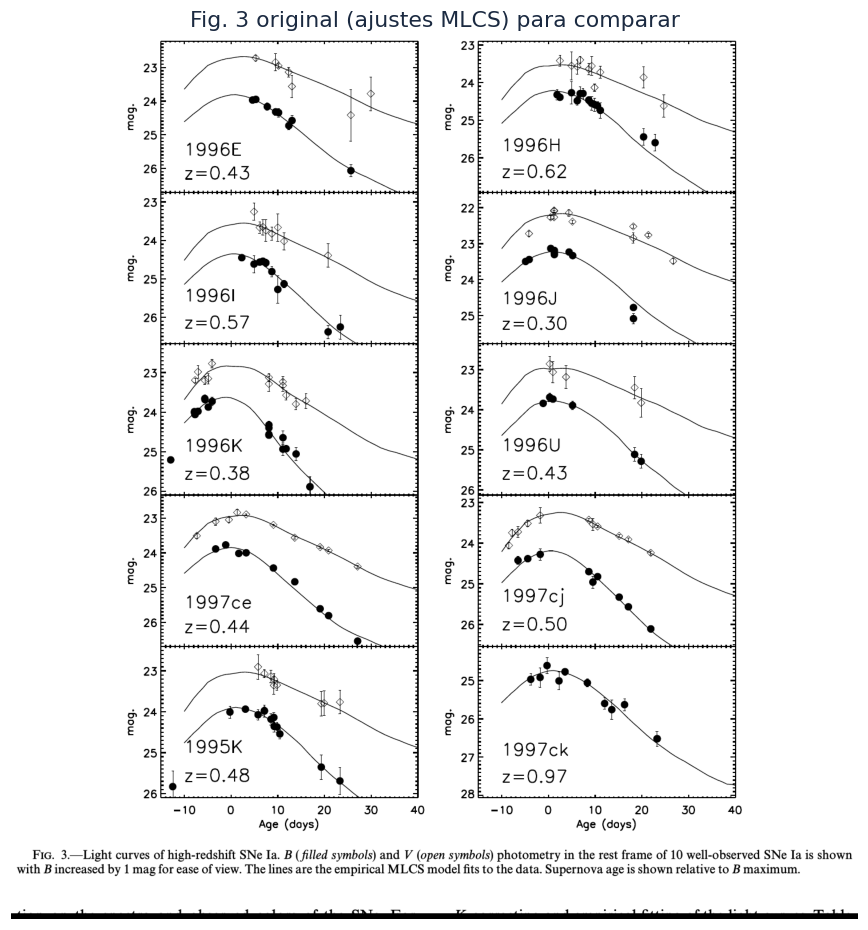

In [14]:
mostrar(ORIG / "fig3_curvas_original.png", "Fig. 3 original (ajustes MLCS) para comparar", ancho=10)

## 4. Distancia luminosa en FLRW

$$E^2(z)=\frac{H^2}{H_0^2}=\Omega_M(1+z)^3+\Omega_k(1+z)^2+\Omega_\Lambda,\qquad \Omega_k=1-\Omega_M-\Omega_\Lambda$$

$$D_L=\frac{c(1+z)}{H_0\sqrt{|\Omega_k|}}\;\mathrm{sinn}\!\left[\sqrt{|\Omega_k|}\int_0^z\frac{dz'}{E(z')}\right],\qquad \mu=5\log_{10}\frac{D_L}{\rm Mpc}+25.$$

Escribimos $D_L = (c/H_0)\,\hat d_L$. La función `dl_hat` calcula $\hat d_L$, que no depende de $H_0$.

Los universos "sin Big Bang" (rebote) y los que recolapsan se detectan con el polinomio $g(x)=x^3E^2=\Omega_M+\Omega_k x+\Omega_\Lambda x^3$, con $x=a/a_0$: si $g$ se anula en $x\in(0,1)$ no hay Big Bang; si se anula para $x>1$, el universo recolapsa.

In [15]:
def sin_big_bang(Om, OL):
    x = np.linspace(1e-4, 1, 400)
    return np.any(Om + (1 - Om - OL) * x + OL * x**3 <= 0)

def recolapsa(Om, OL):
    x = np.linspace(1, 300, 6000)
    return np.any(Om + (1 - Om - OL) * x + OL * x**3 <= 0)

def dl_hat(z, Om, OL, nz=1500):
    # Distancia luminosa en unidades de c/H0. Devuelve None si el modelo no es válido.
    z = np.atleast_1d(z); Ok = 1 - Om - OL
    zg = np.linspace(0, z.max() * 1.001, nz)
    E2 = Om * (1 + zg)**3 + Ok * (1 + zg)**2 + OL
    if np.any(E2 <= 0): return None
    I = np.interp(z, zg, cumulative_trapezoid(1 / np.sqrt(E2), zg, initial=0))
    if abs(Ok) < 1e-8: S = I
    elif Ok > 0:       S = np.sinh(np.sqrt(Ok) * I) / np.sqrt(Ok)
    else:
        arg = np.sqrt(-Ok) * I
        if np.any(arg >= np.pi): return None
        S = np.sin(arg) / np.sqrt(-Ok)
    return (1 + z) * S

def mu_modelo(z, Om, OL, H0):
    return 5 * np.log10(dl_hat(z, Om, OL) * c / H0) + 25

# Chequeo: a bajo z, D_L ≈ cz/H0 [1 + (1 - q0) z / 2]
z = 0.05; Om, OL = 0.3, 0.7; q0 = Om / 2 - OL
print("exacta:", dl_hat(z, Om, OL)[0], " expansión:", z * (1 + (1 - q0) * z / 2))

exacta: 0.051903353104002216  expansión: 0.051937500000000004


## 5. Diagramas de Hubble (Figs. 4 y 5)

Panel superior: $\mu$ contra $z$. Panel inferior: residuos respecto de $(\Omega_M,\Omega_\Lambda)=(0.2,0)$. $H_0$ se fija con el promedio pesado de las cercanas.

MLCS: H0 = 65.6 km/s/Mpc | residuo medio de las lejanas vs (0.2, 0) = 0.24 mag
Δm15(B): H0 = 62.5 km/s/Mpc | residuo medio de las lejanas vs (0.2, 0) = 0.25 mag


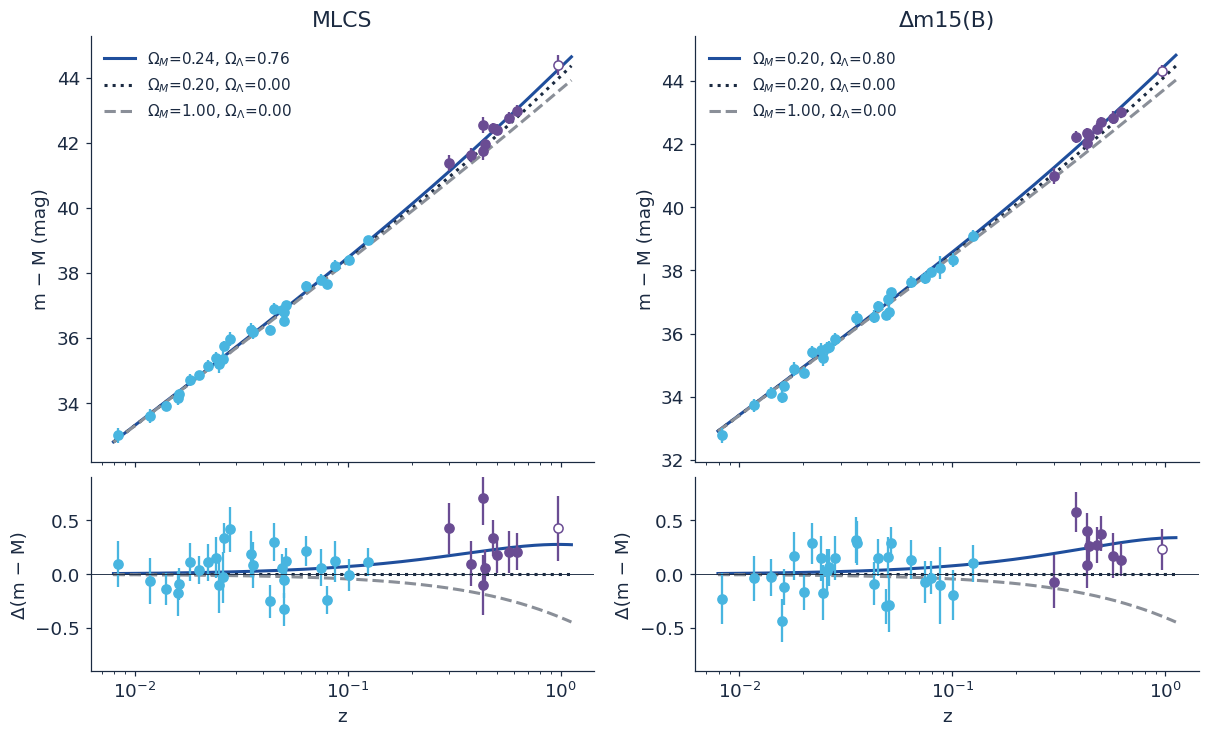

In [16]:
def H0_mejor(df, Om, OL):
    w = 1 / varianza_total(df); base = 5 * np.log10(dl_hat(df.z.values, Om, OL) * c) + 25
    delta = np.sum(w * (df.mu - base)) / np.sum(w)          # mu = base - 5 log10 H0
    return 10**(-delta / 5)

zz = np.logspace(-2.1, 0.05, 300)
fig, axs = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1], "hspace": 0.05})
for j, (met, S, mejor) in enumerate([("MLCS", muestra("MLCS", True), (0.24, 0.76)), ("Δm15(B)", muestra("dm15", True), (0.20, 0.80))]):
    H0 = H0_mejor(S[S.SN != "1997ck"], 0.24, 0.76)
    e = np.sqrt(varianza_total(S))
    a1, a2 = axs[0, j], axs[1, j]
    for (Om, OL), col, ls in [(mejor, AZUL, "-"), ((0.2, 0), TEXTO, ":"), ((1, 0), GRIS, "--")]:
        a1.plot(zz, mu_modelo(zz, Om, OL, H0), color=col, ls=ls, lw=2, label=f"$\\Omega_M$={Om:.2f}, $\\Omega_\\Lambda$={OL:.2f}")
        a2.plot(zz, mu_modelo(zz, Om, OL, H0) - mu_modelo(zz, 0.2, 0, H0), color=col, ls=ls, lw=2)
    for sub, colr, mf in [(~S.lejana, CELESTE, None), (S.lejana & (S.SN != "1997ck"), MORADO, None), (S.SN == "1997ck", MORADO, "white")]:
        d = S[sub]; r = d.mu - mu_modelo(d.z.values, 0.2, 0, H0)
        kw = dict(fmt="o", ms=6, color=colr, ecolor=colr, capsize=0, mfc=mf or colr)
        a1.errorbar(d.z, d.mu, e[sub], **kw); a2.errorbar(d.z, r, e[sub], **kw)
    a1.set_xscale("log"); a1.set_title(met); a1.set_ylabel("m − M (mag)"); a1.legend(frameon=False, fontsize=10, loc="upper left")
    a2.axhline(0, color=TEXTO, lw=0.6); a2.set_ylim(-0.9, 0.9); a2.set_xlabel("z"); a2.set_ylabel("Δ(m − M)")
    lej = S[S.lejana & (S.SN != "1997ck")]
    print(f"{met}: H0 = {H0:.1f} km/s/Mpc | residuo medio de las lejanas vs (0.2, 0) = "
          f"{np.mean(lej.mu - mu_modelo(lej.z.values, 0.2, 0, H0)):.2f} mag")
fig.savefig(FIG / "fig4_5_diagramas_hubble.png"); plt.show()

## 6. Estadística: χ², Bayes y marginalización de $H_0$

$$\chi^2=\sum_i\frac{\left[\mu_{p,i}-\mu_{0,i}\right]^2}{\sigma_{\mu_0,i}^2+\sigma_v^2},\qquad p(\Omega_M,\Omega_\Lambda\,|\,\mu_0)\propto\int e^{-\chi^2/2}\,dH_0 .$$

Como $\mu_p=5\log_{10}\hat d_L+\delta$ con $\delta=5\log_{10}(c/H_0)+25$, el χ² es cuadrático en $\delta$:

$$\chi^2(\delta)=A-2B\delta+C\delta^2\quad\Rightarrow\quad\int e^{-\chi^2/2}d\delta\propto e^{-\tilde\chi^2/2},\qquad \tilde\chi^2=A-\frac{B^2}{C},$$

con $\Delta_i=\mu_{0,i}-5\log_{10}\hat d_{L,i}$, $w_i=1/\sigma_i^2$, $A=\sum w_i\Delta_i^2$, $B=\sum w_i\Delta_i$ y $C=\sum w_i$. Además, la posterior de $\delta$ en cada punto es gaussiana, con media $B/C$ y varianza $1/C$; la usaremos para $H_0$ y la edad.

In [17]:
Oms = np.round(np.arange(0, 2.5001, 0.01), 3)
OLs = np.round(np.arange(-1, 3.0001, 0.02), 3)
OM, OL = np.meshgrid(Oms, OLs)
VALIDO = np.array([[not sin_big_bang(a, b) for a in Oms] for b in OLs])

def grilla_chi2(df):
    w = 1 / varianza_total(df).values; mu = df.mu.values; z = df.z.values
    X2 = np.full(OM.shape, np.nan); BC = np.full(OM.shape, np.nan); CC = np.sum(w)
    for i, b in enumerate(OLs):
        for j, a in enumerate(Oms):
            if not VALIDO[i, j]: continue
            d = dl_hat(z, a, b)
            if d is None or np.any(d <= 0): continue
            D = mu - 5 * np.log10(d)
            A, B = np.sum(w * D * D), np.sum(w * D)
            X2[i, j] = A - B * B / CC; BC[i, j] = B / CC
    return X2, BC, CC

def posterior(X2):
    P = np.exp(-(X2 - np.nanmin(X2)) / 2); P[np.isnan(P)] = 0
    return P / P.sum()

G = {}
for nombre, df in [("MLCS", S_MLCS), ("DM15", S_DM15), ("SNAP", S_SNAP), ("MLCS+97ck", muestra("MLCS", True)), ("DM15+97ck", muestra("dm15", True))]:
    G[nombre] = grilla_chi2(df); print("listo:", nombre)

listo: MLCS
listo: DM15
listo: SNAP
listo: MLCS+97ck
listo: DM15+97ck


In [18]:
def sigmas(p):   # probabilidad -> número de sigmas (gaussiana bilateral)
    from scipy.special import erfinv
    return np.sqrt(2) * erfinv(min(p, 1 - 1e-12))

def chi_1d(df, linea):
    # χ² marginalizado sobre una recta del plano: 'plano' (Ω_M + Ω_Λ = 1), 'L0' (Ω_Λ = 0), 'M02' (Ω_M = 0.2)
    w = 1 / varianza_total(df).values; mu, z = df.mu.values, df.z.values
    if linea == "plano": xs = np.linspace(0, 1, 501); par = [(x, 1 - x) for x in xs]
    if linea == "L0":    xs = np.linspace(-1, 1.5, 501); par = [(x, 0.0) for x in xs]
    if linea == "M02":   xs = np.linspace(-1, 3, 801); par = [(0.2, x) for x in xs]
    chi = []
    for a, b in par:
        d = dl_hat(z, a, b)
        if d is None or np.any(d <= 0): chi.append(np.nan); continue
        D = mu - 5 * np.log10(d); chi.append(np.sum(w * D * D) - np.sum(w * D)**2 / np.sum(w))
    return xs, np.array(chi)

def resumen_1d(dfs, linea):
    xs, chi = chi_1d(dfs[0], linea)
    for d in dfs[1:]: chi = chi + chi_1d(d, linea)[1]     # muestras independientes: se suman los χ²
    p = np.exp(-(chi - np.nanmin(chi)) / 2); p[np.isnan(p)] = 0; p /= p.sum()
    m = np.sum(xs * p); s = np.sqrt(np.sum((xs - m)**2 * p))
    return m, s, np.nanmin(chi) / (sum(len(d) for d in dfs) - 2 * len(dfs))

def fmt_p(p):
    return (f"> 99.9% ({sigmas(p):.1f}σ)" if p > 0.999 else f"{100*p:.1f}% ({sigmas(p):.1f}σ)")

filas = []
for nombre, X2s, dfs in [("MLCS + snapshot (15)", [G["MLCS"][0], G["SNAP"][0]], [S_MLCS, S_SNAP]),
                         ("Δm15 + snapshot (15)", [G["DM15"][0], G["SNAP"][0]], [S_DM15, S_SNAP]),
                         ("MLCS (9)", [G["MLCS"][0]], [S_MLCS]),
                         ("Δm15 (9)", [G["DM15"][0]], [S_DM15])]:
    P = posterior(sum(X2s))
    pL = P[OL > 0].sum(); pq = P[OL > OM / 2].sum()
    q0 = OM / 2 - OL; q0m = np.sum(q0 * P); q0s = np.sqrt(np.sum((q0 - q0m)**2 * P))
    fl, l0, m02 = (resumen_1d(dfs, k) for k in ("plano", "L0", "M02"))
    filas.append({"método": nombre,
                  "P(Ω_Λ>0)": fmt_p(pL), "P(q0<0)": fmt_p(pq),
                  "q0": f"{q0m:.2f} ± {q0s:.2f}",
                  "Ω_M (plano)": f"{fl[0]:.2f} ± {fl[1]:.2f}",
                  "Ω_M (Ω_Λ≡0)": f"{l0[0]:.2f} ± {l0[1]:.2f}",
                  "Ω_Λ (Ω_M≡0.2)": f"{m02[0]:.2f} ± {m02[1]:.2f}",
                  "χ²_ν (plano)": f"{fl[2]:.2f}"})
RES = pd.DataFrame(filas).set_index("método"); RES

,P(Ω_Λ>0),P(q0<0),q0,Ω_M (plano),Ω_M (Ω_Λ≡0),Ω_Λ (Ω_M≡0.2),χ²_ν (plano)
método,,,,,,,
MLCS + snapshot (15),99.5% (2.8σ),99.3% (2.7σ),-0.89 ± 0.39,0.30 ± 0.10,-0.27 ± 0.20,0.59 ± 0.22,1.17
Δm15 + snapshot (15),> 99.9% (3.9σ),> 99.9% (3.7σ),-1.26 ± 0.37,0.22 ± 0.09,-0.41 ± 0.17,0.79 ± 0.19,1.08
MLCS (9),99.4% (2.8σ),99.0% (2.6σ),-0.88 ± 0.41,0.29 ± 0.11,-0.33 ± 0.21,0.61 ± 0.23,1.19
Δm15 (9),> 99.9% (3.8σ),> 99.9% (3.7σ),-1.31 ± 0.41,0.20 ± 0.09,-0.48 ± 0.18,0.82 ± 0.20,1.05


Compara con la Tabla 8 del paper. Por ejemplo, MLCS + snapshot da $P(\Omega_\Lambda>0)=99.7\%$, Ω_M (plano) = 0.28 ± 0.10 y Ω_Λ(Ω_M≡0.2) = 0.65 ± 0.22. Las diferencias pequeñas vienen de la grilla, del prior en $H_0$ y de cómo se resume cada distribución (aquí: media ± desviación estándar).

## 7. Contornos en el plano $(\Omega_M,\Omega_\Lambda)$ (Figs. 6 y 7)

Los niveles son regiones de máxima densidad que encierran 68.3 %, 95.4 % y 99.7 % de la probabilidad. Las líneas en gris marcan $q_0=-0.5, 0, 0.5$; la recta morada separa aceleración y desaceleración. Los contornos punteados incluyen SN 1997ck.

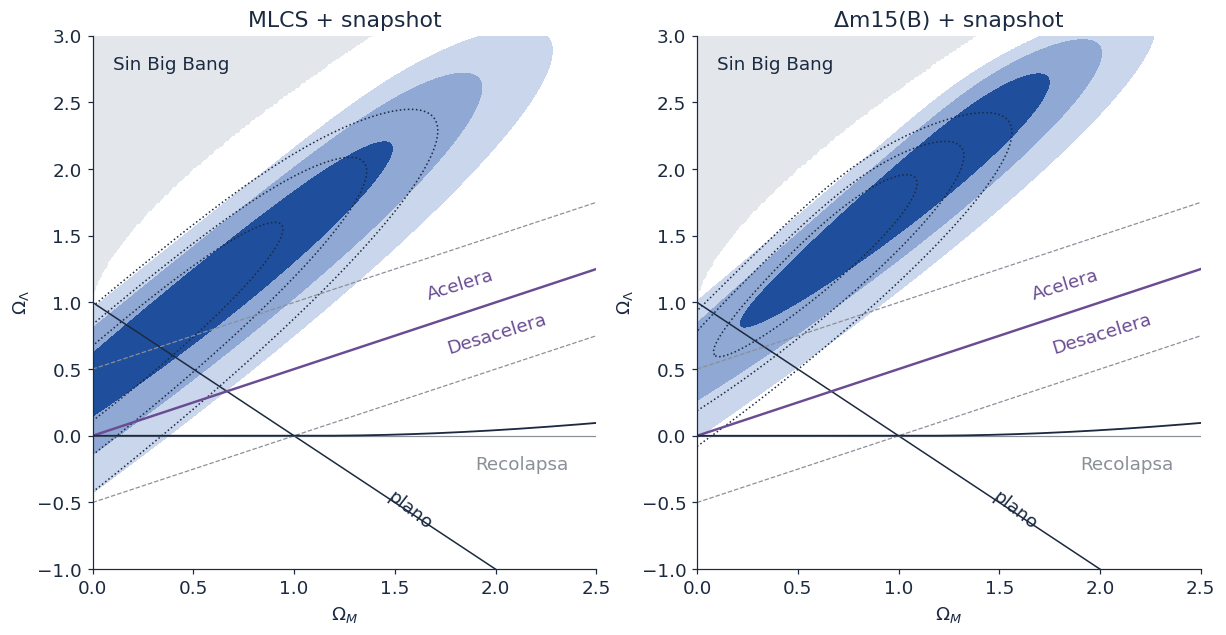

In [19]:
def niveles(P, probs=(0.683, 0.954, 0.997)):
    f = np.sort(P.ravel())[::-1]; cs = np.cumsum(f)
    return sorted([f[np.searchsorted(cs, p)] for p in probs])

xs = np.linspace(0, 2.5, 300)
borde_recol = []
for a in xs:   # recolapso: menor Ω_Λ que evita que H² se anule en el futuro
    lo, hi = -1.0, 1.0
    for _ in range(35):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if not recolapsa(a, mid) else (mid, hi)
    borde_recol.append(hi)

fig, axs = plt.subplots(1, 2, figsize=(13, 6.3))
for ax, met, extra in [(axs[0], "MLCS", "MLCS+97ck"), (axs[1], "DM15", "DM15+97ck")]:
    P = posterior(G[met][0] + G["SNAP"][0]); Pk = posterior(G[extra][0] + G["SNAP"][0])
    ax.contourf(Oms, OLs, (~VALIDO).astype(float), levels=[0.5, 1.5], colors=["#E3E6EA"])
    ax.contourf(Oms, OLs, P, levels=niveles(P) + [P.max() * 1.01], colors=["#C9D6EC", "#8FA8D4", AZUL])
    ax.contour(Oms, OLs, Pk, levels=niveles(Pk), colors=[TEXTO], linestyles=":", linewidths=1)
    ax.plot(xs, 1 - xs, color=TEXTO, lw=1); ax.axhline(0, color=GRIS, lw=0.8)
    for q, ls in [(-0.5, "--"), (0.5, "--")]: ax.plot(xs, xs / 2 - q, color=GRIS, ls=ls, lw=0.8)
    ax.plot(xs, xs / 2, color=MORADO, lw=1.6)
    ax.plot(xs, borde_recol, color=TEXTO, lw=1.2)
    ax.text(0.1, 2.75, "Sin Big Bang"); ax.text(1.65, 1.02, "Acelera", color=MORADO, rotation=17); ax.text(1.75, 0.62, "Desacelera", color=MORADO, rotation=17)
    ax.text(1.9, -0.25, "Recolapsa", color=GRIS); ax.text(1.45, -0.7, "plano", rotation=-38)
    ax.set_xlim(0, 2.5); ax.set_ylim(-1, 3); ax.set_xlabel("$\\Omega_M$"); ax.set_ylabel("$\\Omega_\\Lambda$")
    ax.set_title("MLCS + snapshot" if met == "MLCS" else "Δm15(B) + snapshot")
fig.savefig(FIG / "fig6_7_contornos.png"); plt.show()

## 8. Edad dinámica (Figs. 8 y 9)

$$t_0=\frac{1}{H_0}\int_0^\infty\frac{dz}{(1+z)\,E(z)} .$$

Para la PDF de $t_0$ hacemos Monte Carlo:

1. sorteamos puntos $(\Omega_M,\Omega_\Lambda)$ según la posterior;
2. en cada punto sorteamos $\delta\sim\mathcal N(B/C,\,1/C)$, lo que da $H_0=c\,10^{-(\delta-25)/5}$;
3. calculamos $t_0$ para cada muestra.

El factor de conversión es $1/H_0 = 977.8/H_0$ Gyr, con $H_0$ en km/s/Mpc.

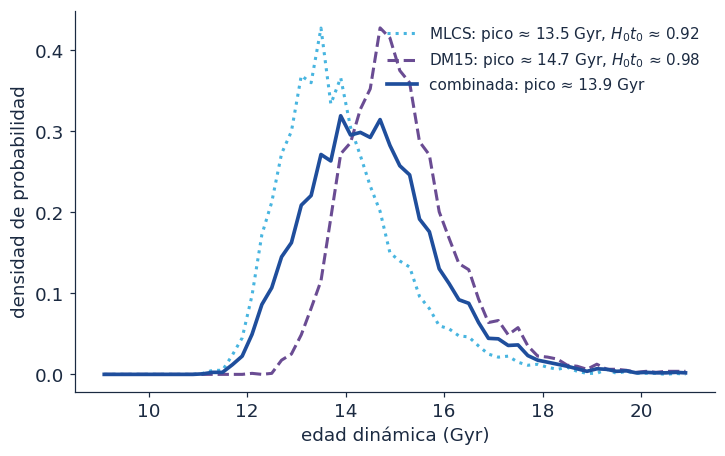

In [20]:
def H0t0(Om, OL):
    # Misma integral escrita en el factor de escala a = 1/(1+z): H0 t0 = ∫_0^1 da / sqrt(Ω_M/a + Ω_k + Ω_Λ a²)
    with warnings.catch_warnings(), np.errstate(all="ignore"):
        warnings.simplefilter("ignore")
        return quad(lambda a: 1 / np.sqrt(Om / a + (1 - Om - OL) + OL * a**2), 1e-10, 1, limit=200)[0]

rng = np.random.default_rng(1998)
def muestras_edad(met, n=4000):
    X2, BC, CC = G[met]; P = posterior(X2 + G["SNAP"][0])   # snapshot sólo restringe Ω, no H0
    idx = rng.choice(P.size, size=n, p=P.ravel())
    om, ol, bc = OM.ravel()[idx], OL.ravel()[idx], BC.ravel()[idx]
    delta = rng.normal(bc, 1 / np.sqrt(CC))
    H0 = c * 10**(-(delta - 25) / 5)
    cache = {}
    ht = np.array([cache.setdefault((a, b), H0t0(a, b)) for a, b in zip(om, ol)])
    return ht * 977.8 / H0, ht

fig, ax = plt.subplots(figsize=(7.5, 4.5)); bins = np.linspace(9, 21, 61); dens = {}
for met, col, ls in [("MLCS", CELESTE, ":"), ("DM15", MORADO, "--")]:
    t, ht = muestras_edad(met)
    h, e = np.histogram(t, bins, density=True); dens[met] = h
    ax.plot(0.5 * (e[1:] + e[:-1]), h, color=col, ls=ls, lw=2, label=f"{met}: pico ≈ {0.5*(e[1:]+e[:-1])[h.argmax()]:.1f} Gyr, $H_0t_0$ ≈ {np.median(ht):.2f}")
comb = 0.5 * (dens["MLCS"] + dens["DM15"]); cen = 0.5 * (e[1:] + e[:-1])
ax.plot(cen, comb, color=AZUL, lw=2.4, label=f"combinada: pico ≈ {cen[comb.argmax()]:.1f} Gyr")
ax.set_xlabel("edad dinámica (Gyr)"); ax.set_ylabel("densidad de probabilidad"); ax.legend(frameon=False, fontsize=10)
fig.savefig(FIG / "fig8_pdf_edad.png"); plt.show()

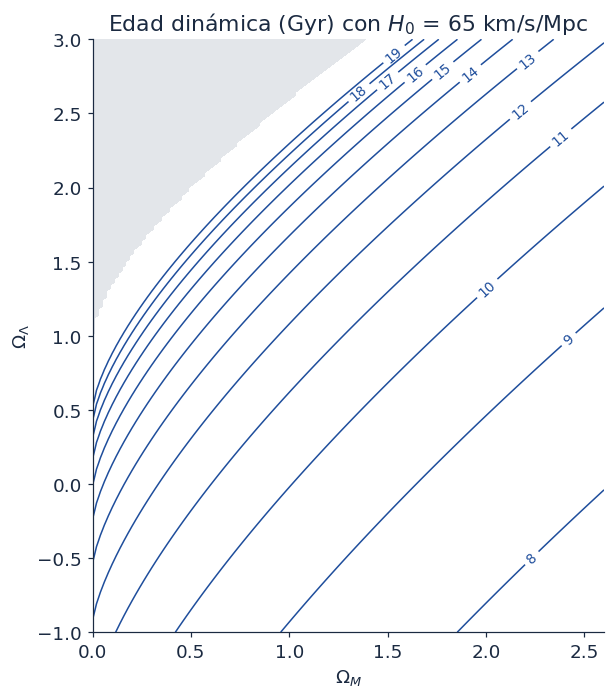

In [21]:
om9 = np.linspace(0, 2.6, 131); ol9 = np.linspace(-1, 3, 201)
T0 = np.full((len(ol9), len(om9)), np.nan)
for i, b in enumerate(ol9):
    for j, a in enumerate(om9):
        if not sin_big_bang(a, b): T0[i, j] = H0t0(a, b) * 977.8 / 65.0
fig, ax = plt.subplots(figsize=(6, 7))
cs = ax.contour(om9, ol9, T0, levels=np.arange(8, 20), colors=[AZUL], linewidths=1)
ax.clabel(cs, fmt="%d", fontsize=9)
ax.contourf(om9, ol9, np.isnan(T0).astype(float), levels=[0.5, 1.5], colors=["#E3E6EA"])
ax.set_xlabel("$\\Omega_M$"); ax.set_ylabel("$\\Omega_\\Lambda$"); ax.set_title("Edad dinámica (Gyr) con $H_0$ = 65 km/s/Mpc")
fig.savefig(FIG / "fig9_lineas_edad.png"); plt.show()

## 9. Parámetros de forma de las curvas de luz (Fig. 10)

Si las supernovas lejanas fueran una población distinta (evolución), sus distribuciones de $\Delta$ (MLCS) o $\Delta m_{15}(B)$ serían diferentes de las cercanas. El test de Kolmogorov–Smirnov compara ambas distribuciones.

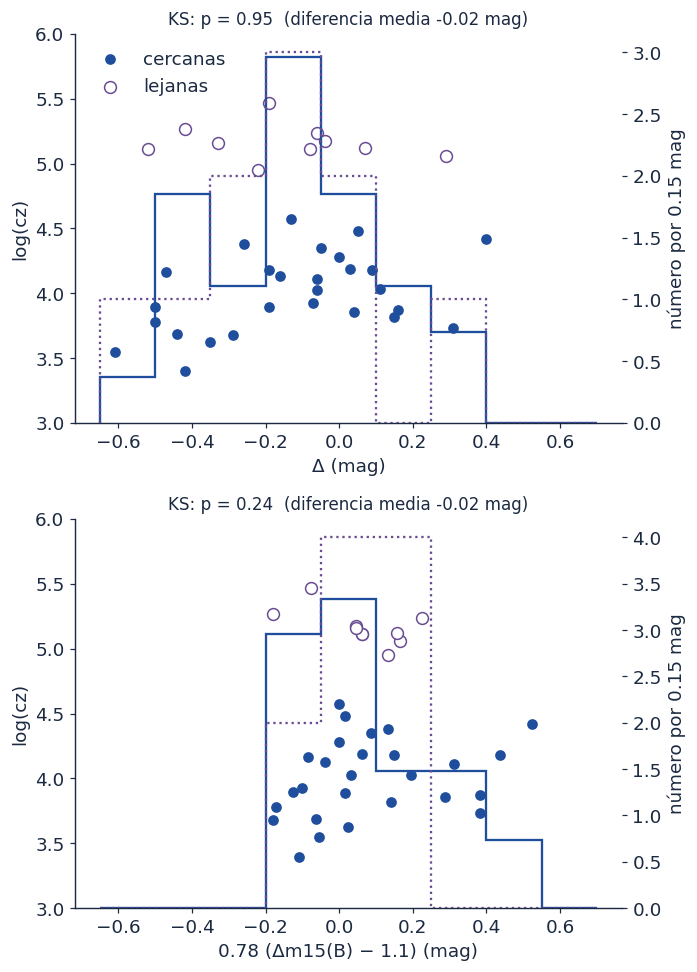

In [22]:
from scipy.stats import ks_2samp
t10, t5d, t6d = T["t10"], T["t5"], T["t6"]
fig, axs = plt.subplots(2, 1, figsize=(6.5, 9))
for ax, xl, xh, lab, xform in [
        (axs[0], t10.Delta_MLCS, t5d.Delta, "Δ (mag)", lambda x: x),
        (axs[1], t10.dm15B, t6d.dm15B, "0.78 (Δm15(B) − 1.1) (mag)", lambda x: 0.78 * (x - 1.1))]:
    xl, xh = xform(xl), xform(xh)
    ax.scatter(xl, t10.log_cz, color=AZUL, label="cercanas")
    ax.scatter(xh, np.log10(c * t5d.z), facecolor="white", edgecolor=MORADO, s=60, label="lejanas")
    ax2 = ax.twinx(); b = np.arange(-0.65, 0.8, 0.15)
    ax2.hist(xl, b, histtype="step", color=AZUL, weights=np.full(len(xl), 1 / 2.7), lw=1.5)
    ax2.hist(xh, b, histtype="step", color=MORADO, ls=":", lw=1.5); ax2.set_ylabel("número por 0.15 mag")
    ks = ks_2samp(xl, xh)
    ax.set_xlabel(lab); ax.set_ylabel("log(cz)"); ax.set_ylim(3, 6)
    ax.set_title(f"KS: p = {ks.pvalue:.2f}  (diferencia media {np.mean(xh) - np.mean(xl):+.2f} mag)", fontsize=11)
axs[0].legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "fig10_parametros_forma.png"); plt.show()

## 10. Resumen

- Las lejanas son ~0.25 mag (MLCS) o ~0.28 mag (Δm15) más débiles que en un universo con $\Omega_M=0.2$ y $\Omega_\Lambda=0$.
- Con solo $\Omega_M\ge0$ como prior, $\Omega_\Lambda>0$ y $q_0<0$ quedan favorecidos con unos 3 a 4σ.
- Si se fuerza $\Omega_\Lambda=0$, el mejor ajuste exige $\Omega_M<0$, que no es físico.
- La edad dinámica sale ~14 Gyr, con $H_0t_0\approx0.9$.

Las figuras quedan guardadas en la carpeta `figuras/`.

In [23]:
RES

,P(Ω_Λ>0),P(q0<0),q0,Ω_M (plano),Ω_M (Ω_Λ≡0),Ω_Λ (Ω_M≡0.2),χ²_ν (plano)
método,,,,,,,
MLCS + snapshot (15),99.5% (2.8σ),99.3% (2.7σ),-0.89 ± 0.39,0.30 ± 0.10,-0.27 ± 0.20,0.59 ± 0.22,1.17
Δm15 + snapshot (15),> 99.9% (3.9σ),> 99.9% (3.7σ),-1.26 ± 0.37,0.22 ± 0.09,-0.41 ± 0.17,0.79 ± 0.19,1.08
MLCS (9),99.4% (2.8σ),99.0% (2.6σ),-0.88 ± 0.41,0.29 ± 0.11,-0.33 ± 0.21,0.61 ± 0.23,1.19
Δm15 (9),> 99.9% (3.8σ),> 99.9% (3.7σ),-1.31 ± 0.41,0.20 ± 0.09,-0.48 ± 0.18,0.82 ± 0.20,1.05
